<a href="https://colab.research.google.com/github/FunGrape/Labs_ML_Demchyshyn/blob/main/%D0%9B%D0%A05_%D0%94%D0%B5%D0%BC%D1%87%D0%B8%D1%88%D0%B8%D0%BD_4_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

In [ ]:
!pip install kagglehub -q
import kagglehub
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")
print(path, os.listdir(path))


100%|██████████| 194k/194k [00:00<00:00, 720kB/s]

Extracting files...
/root/.cache/kagglehub/datasets/yug201/daily-climate-time-series-data-delhi-india/versions/1 ['kaggel_weather_2013_to_2024.csv']


In [ ]:
csv_file = "kaggel_weather_2013_to_2024.csv"
df = pd.read_csv(os.path.join(path, csv_file))
df.head()


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Підготовка даних

In [ ]:
date_col = [c for c in df.columns if c.lower() in ("date", "datetime")][0]
df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).drop_duplicates(subset=date_col)
df = df.set_index(date_col)
df.index.name = "DATE"
df = df.select_dtypes(include="number")

candidates = ["TAVG", "meantemp", "temperature", "temp", "TMAX"]
TARGET = next(c for c in candidates if c in df.columns)
print("Цільова змінна:", TARGET)

Цільова змінна: temp


In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3556 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3556 non-null   int64  
 1   tempmax                3556 non-null   float64
 2   tempmin                3556 non-null   float64
 3   temp                   3556 non-null   float64
 4   feelslikemax           3556 non-null   float64
 5   feelslikemin           3556 non-null   float64
 6   feelslike              3556 non-null   float64
 7   humidity               3556 non-null   float64
 8   precip                 3556 non-null   float64
 9   precipprob             3556 non-null   int64  
 10  precipcover            3556 non-null   float64
 11  windspeed              3556 non-null   float64
 12  sealevelpressure       3556 non-null   float64
 13  Year                   3556 non-null   int64  
 14  month                  3556 non-null  

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,...,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000
mean,1777.764904,31.365073,20.073847,25.400984,34.277925,20.936699,27.304921,63.764258,2.459725,23.143982,...,19.268560,26.868673,1919.270807,1241.006375,1554.504165,2137.916848,1300.059699,1697.056932,11.291226,195.599722
std,1027.010475,7.073447,7.568369,7.325185,9.652163,9.005246,9.302266,18.124170,10.637671,42.181212,...,3.219426,14.911475,525.858317,580.762376,539.244300,839.882256,692.667235,754.684620,3.622730,55.575946
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,888.750000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1542.450000,759.282500,1120.135000,1534.475000,751.912500,1113.712500,8.300000,164.448043
50%,1777.500000,32.950000,22.000000,27.700000,35.350000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.440000,1078.520000,1420.300000,1845.635000,1081.015000,1423.715000,11.600000,180.579833
75%,2667.250000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.527500,1752.770000,2035.927500,2764.697500,1864.350000,2315.295000,14.100000,233.701315
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


In [ ]:
print("Пропуски до обробки:\n", df.isna().sum())
df = df.asfreq("D")
df = df.interpolate(method="time").ffill().bfill()
print("Пропуски після обробки:", df.isna().sum().sum())
ts = df[TARGET]

Пропуски до обробки:
 Unnamed: 0               0
tempmax                  0
tempmin                  0
temp                     0
feelslikemax             0
feelslikemin             0
feelslike                0
humidity                 0
precip                   0
precipprob               0
precipcover              0
windspeed                0
sealevelpressure         0
Year                     0
month                    0
dayofweek                0
dayofyear                0
year-2000                0
weekofyear               0
tempmax_humidity         0
tempmin_humidity         0
temp_humidity            0
feelslikemax_humidity    0
feelslikemin_humidity    0
feelslike_humidity       0
temp_range               0
heat_index               0
dtype: int64
Пропуски після обробки: 0


Графік температури

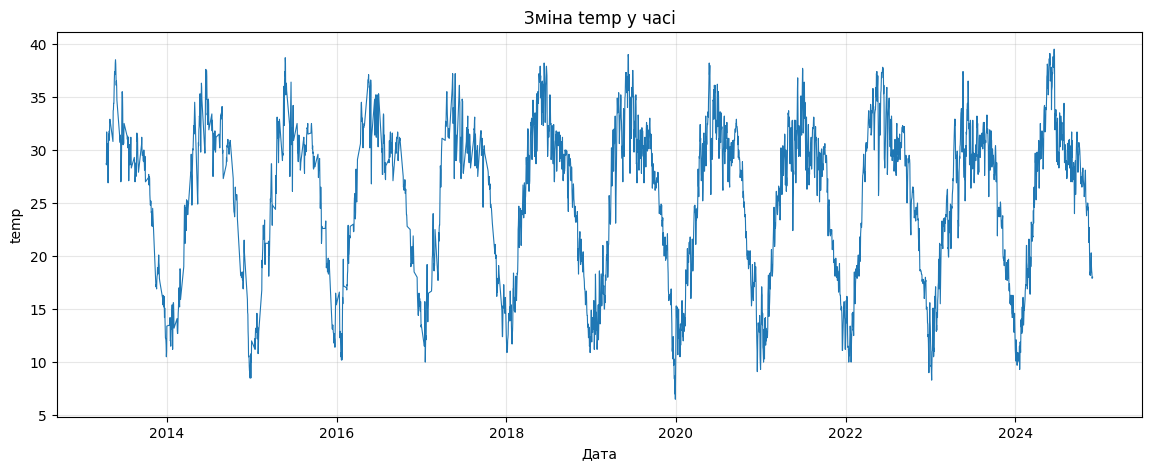

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(ts, linewidth=0.8)
plt.title(f"Зміна {TARGET} у часі")
plt.xlabel("Дата")
plt.ylabel(TARGET)
plt.grid(alpha=0.3)
plt.show()

Ковзне середнє

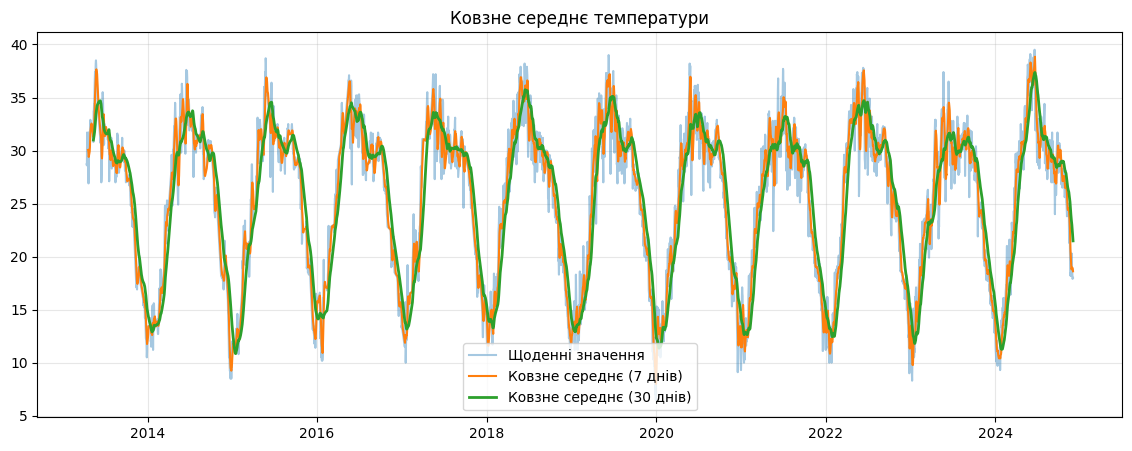

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(ts, alpha=0.4, label="Щоденні значення")
plt.plot(ts.rolling(7).mean(), label="Ковзне середнє (7 днів)")
plt.plot(ts.rolling(30).mean(), label="Ковзне середнє (30 днів)", linewidth=2)
plt.title("Ковзне середнє температури")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Розподіл температури

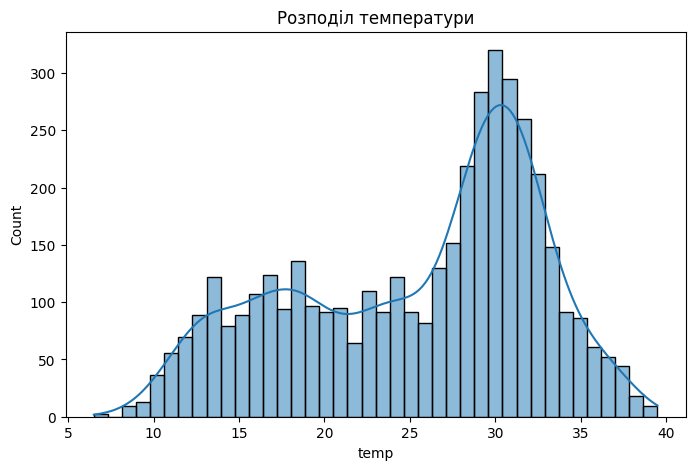

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(ts, bins=40, kde=True)
plt.title("Розподіл температури")
plt.xlabel(TARGET)
plt.show()

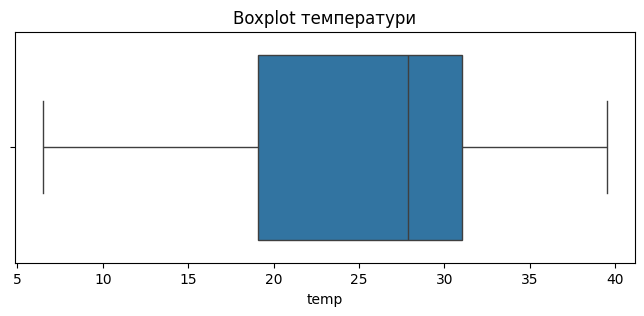

In [ ]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=ts)
plt.title("Boxplot температури")
plt.show()

Аналіз автокореляції
ACF

PACF

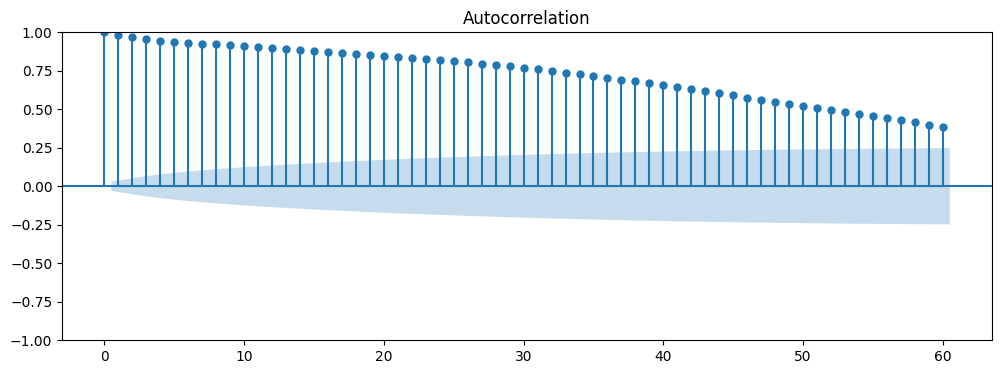

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(ts, lags=60, ax=ax)
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

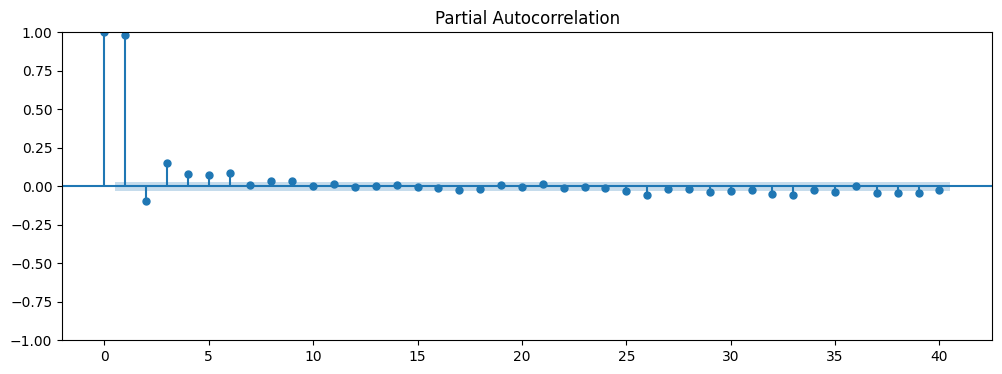

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(ts, lags=40, method="ywm", ax=ax)
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [ ]:
split = int(len(ts) * 0.8)
train, test = ts.iloc[:split], ts.iloc[split:]
print("Train:", train.index.min().date(), "-", train.index.max().date(), len(train))
print("Test: ", test.index.min().date(), "-", test.index.max().date(), len(test))

Train: 2013-04-14 - 2022-08-03 3399
Test:  2022-08-04 - 2024-11-30 850


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [ ]:
adf_p = adfuller(train)[1]
print("ADF p-value:", round(adf_p, 4), "(< 0.05 => ряд стаціонарний, d=0)")

arima_fit = ARIMA(train, order=(2, 0, 2)).fit()
arima_pred = arima_fit.forecast(steps=len(test))
arima_pred.index = test.index

ADF p-value: 0.017 (< 0.05 => ряд стаціонарний, d=0)


In [ ]:
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 3399
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -5408.981
Date:                Sun, 22 Nov 2026   AIC                          10829.961
Time:                        20:36:57   BIC                          10866.749
Sample:                    04-14-2013   HQIC                         10843.110
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         25.8299      2.284     11.309      0.000      21.354      30.306
ar.L1          1.5640      0.046     33.860      0.000       1.473       1.655
ar.L2         -0.5667      0.046    -12.412      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

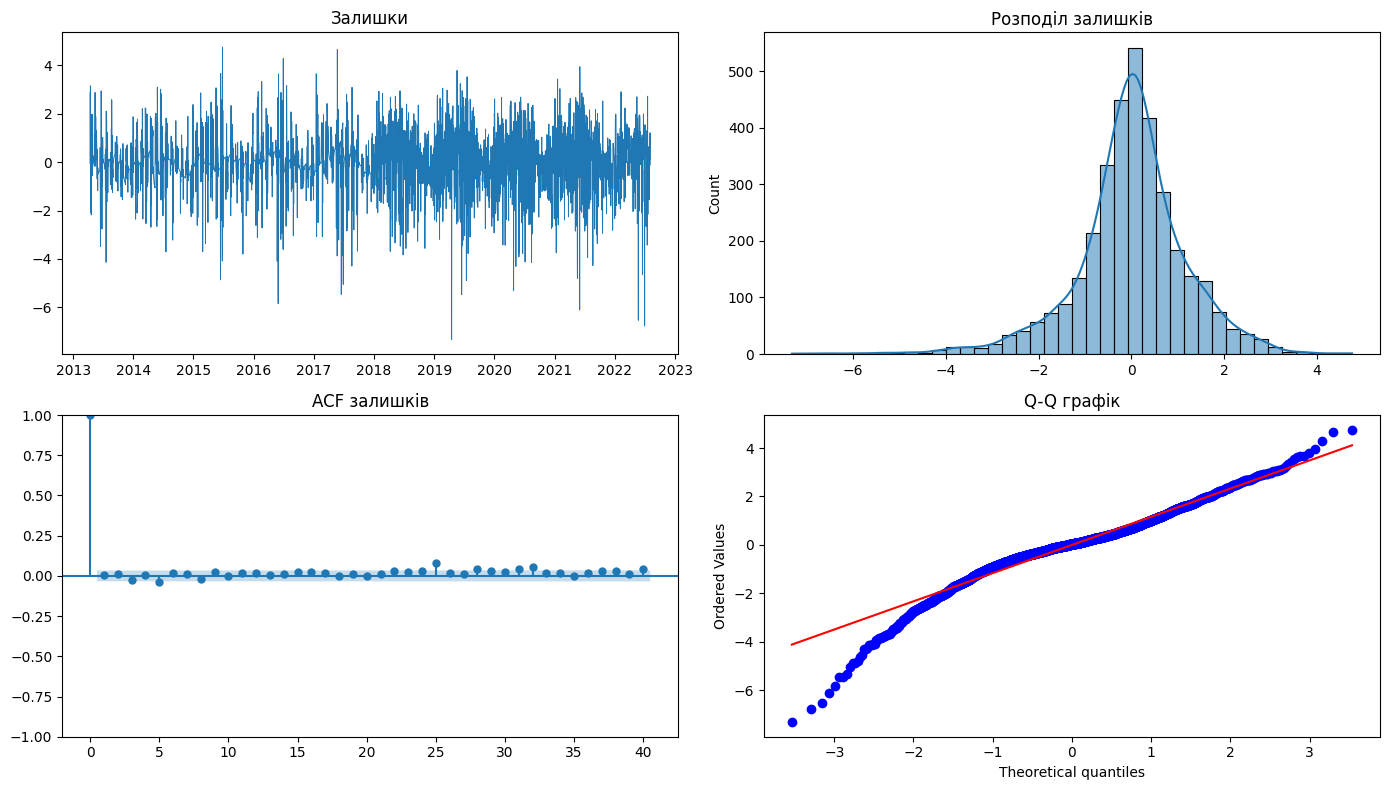

In [ ]:
from scipy import stats

resid = arima_fit.resid
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].plot(resid, linewidth=0.7)
axes[0, 0].set_title("Залишки")
sns.histplot(resid, bins=40, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Розподіл залишків")
plot_acf(resid, lags=40, ax=axes[1, 0])
axes[1, 0].set_title("ACF залишків")
stats.probplot(resid, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q графік")
plt.tight_layout()
plt.show()

In [ ]:
def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE, %": mape(y_true, y_pred),
    }

results = {}
results["ARIMA"] = evaluate(test, arima_pred)
print(results["ARIMA"])

{'MAE': 5.8143647557374765, 'RMSE': np.float64(7.192127126609893), 'MAPE, %': np.float64(30.581676164533604)}


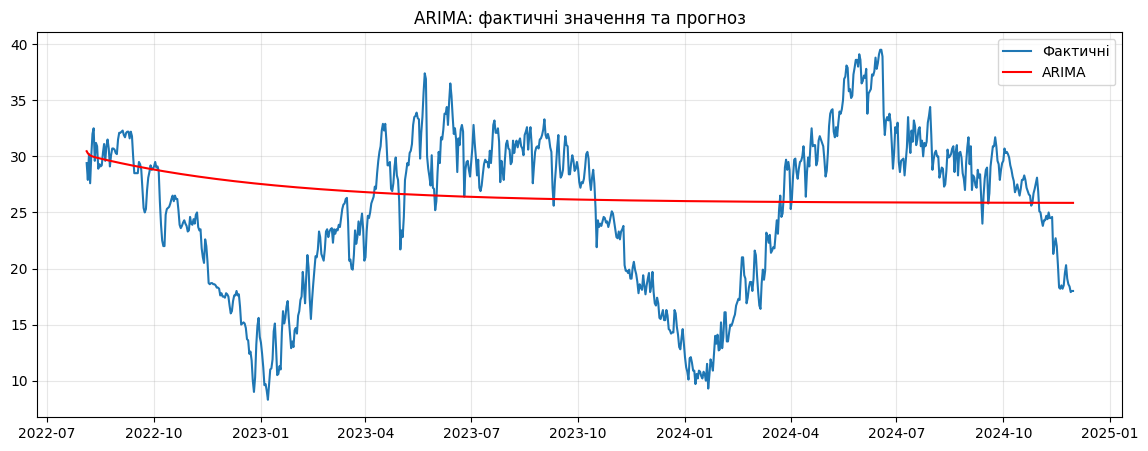

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(test, label="Фактичні")
plt.plot(arima_pred, label="ARIMA", color="red")
plt.title("ARIMA: фактичні значення та прогноз")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [ ]:
prophet_train = train.reset_index()
prophet_train.columns = ["ds", "y"]
prophet_test = test.reset_index()
prophet_test.columns = ["ds", "y"]

In [ ]:
!pip install prophet -q
from prophet import Prophet

prophet_model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
prophet_model.fit(prophet_train)

Прогноз

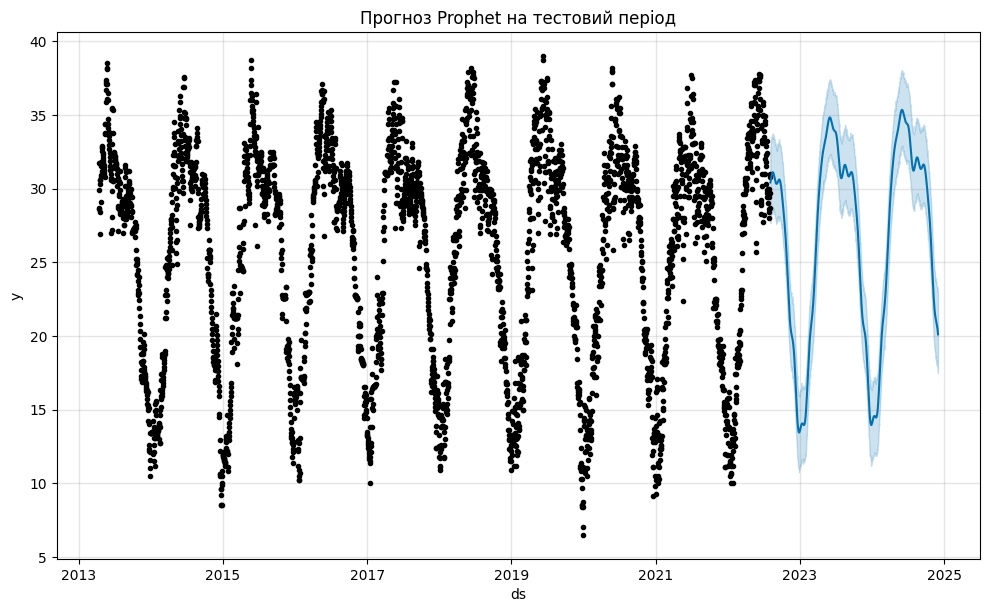

In [ ]:
forecast = prophet_model.predict(prophet_test[["ds"]])
prophet_pred = pd.Series(forecast["yhat"].values, index=test.index)
prophet_model.plot(forecast)
plt.title("Прогноз Prophet на тестовий період")
plt.show()

In [ ]:
results["Prophet"] = evaluate(test, prophet_pred)
print(results["Prophet"])

{'MAE': 2.051367571392372, 'RMSE': np.float64(2.6295744727099013), 'MAPE, %': np.float64(9.264566477555551)}


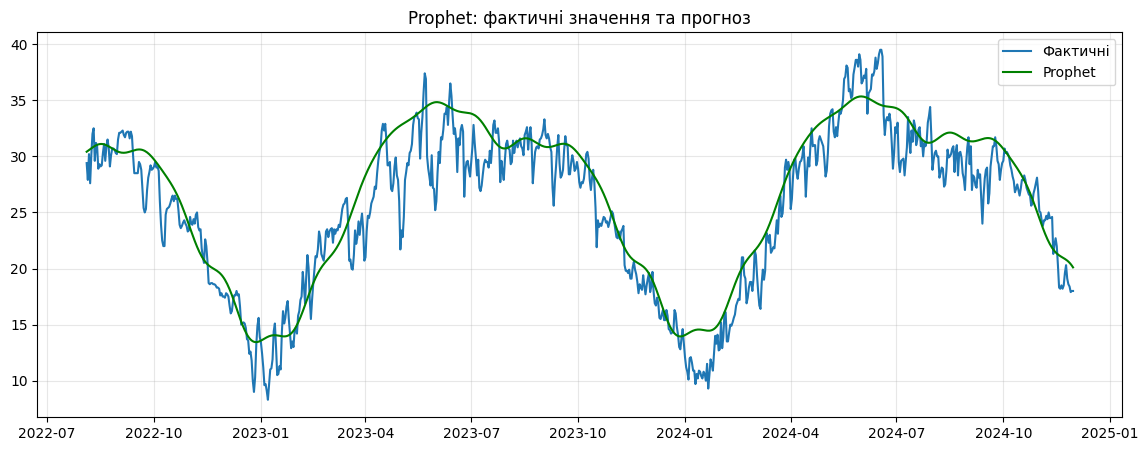

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(test, label="Фактичні")
plt.plot(prophet_pred, label="Prophet", color="green")
plt.title("Prophet: фактичні значення та прогноз")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

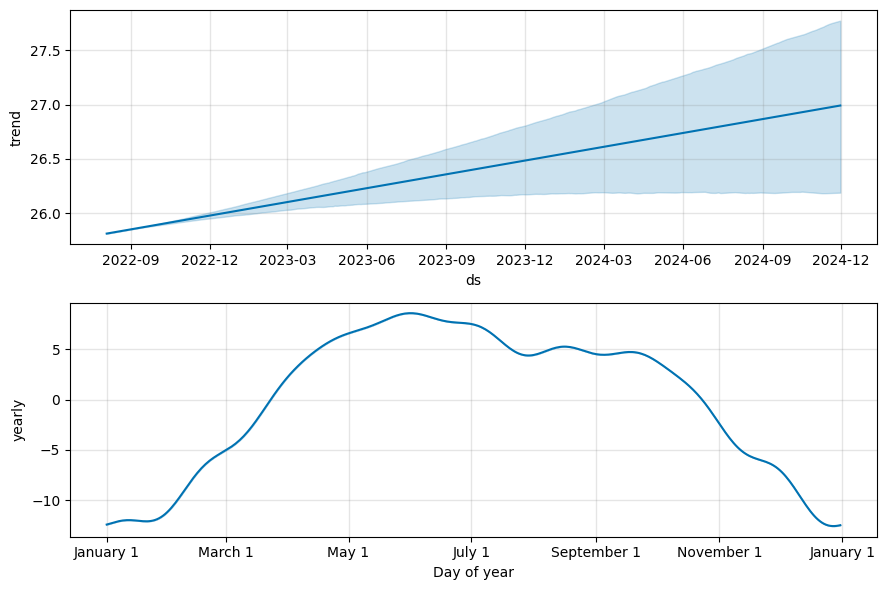

In [ ]:
prophet_model.plot_components(forecast)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [ ]:
window = 30
scaler = MinMaxScaler()
scaler.fit(train.values.reshape(-1, 1))
scaled = scaler.transform(ts.values.reshape(-1, 1))

def make_sequences(data, window):
    X, y = [], []
    for i in range(len(data) - window):
        X.append(data[i:i + window])
        y.append(data[i + window])
    return np.array(X), np.array(y)

X_all, y_all = make_sequences(scaled, window)
print(X_all.shape, y_all.shape)

(4219, 30, 1) (4219, 1)


In [ ]:
n_train_seq = split - window
X_train, y_train = X_all[:n_train_seq], y_all[:n_train_seq]
X_test, y_test = X_all[n_train_seq:], y_all[n_train_seq:]
print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (3369, 30, 1) X_test: (850, 30, 1)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)
np.random.seed(42)

lstm_model = Sequential([
    Input(shape=(window, 1)),
    LSTM(64),
    Dropout(0.2),
    Dense(1),
])
lstm_model.compile(optimizer="adam", loss="mse")

Epoch 1/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - loss: 0.0292 - val_loss: 0.0047
Epoch 2/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0070 - val_loss: 0.0041
Epoch 3/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0057 - val_loss: 0.0040
Epoch 4/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0053 - val_loss: 0.0038
Epoch 5/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0050 - val_loss: 0.0036
Epoch 6/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0049 - val_loss: 0.0035
Epoch 7/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0048 - val_loss: 0.0035
Epoch 8/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0045 - val_loss: 0.0033
Epoch 9/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0046 - val_loss: 0.0033
Epoch 10/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0043 - val_loss: 0.0032
Epoch 11/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0041 - val_loss: 0.0029
Epoch 12/50
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0041 - va

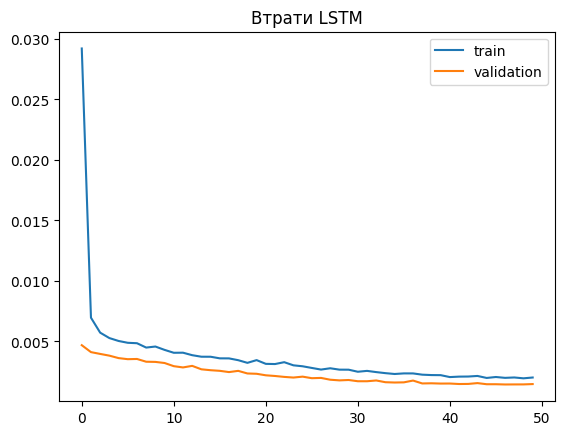

In [ ]:
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = lstm_model.fit(X_train, y_train, epochs=50, batch_size=32,
                         validation_split=0.1, callbacks=[early_stop], verbose=1)

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Втрати LSTM")
plt.legend()
plt.show()

In [ ]:
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,885 (198.77 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 33,924 (132.52 KB)

In [ ]:
lstm_scaled_pred = lstm_model.predict(X_test)
lstm_pred_values = scaler.inverse_transform(lstm_scaled_pred).ravel()

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [ ]:
lstm_index = ts.index[split:]
lstm_pred = pd.Series(lstm_pred_values, index=lstm_index)
print("Довжини збігаються:", len(lstm_pred) == len(test))

Довжини збігаються: True


In [ ]:
results["LSTM"] = evaluate(test, lstm_pred)
print(results["LSTM"])

{'MAE': 0.9568075101515826, 'RMSE': np.float64(1.250122131790895), 'MAPE, %': np.float64(4.171872714333913)}


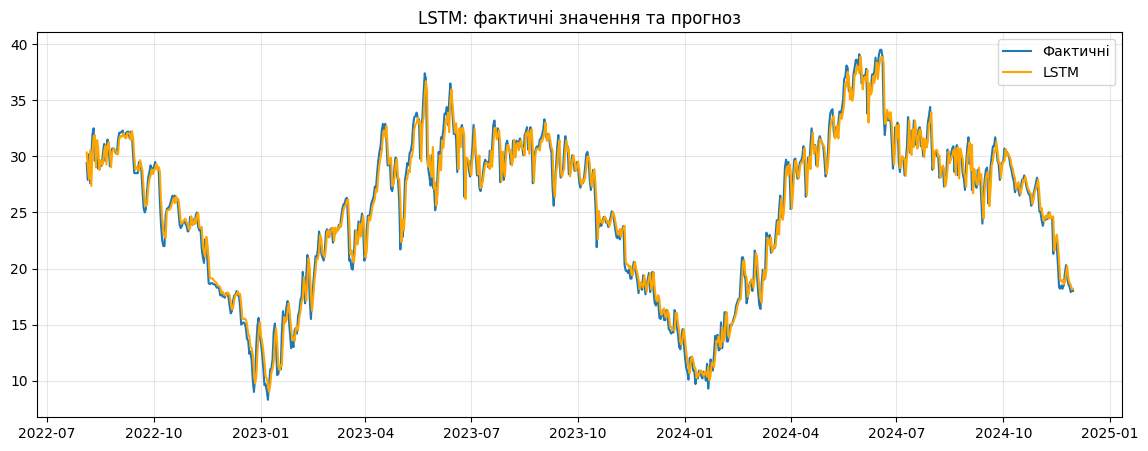

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(test, label="Фактичні")
plt.plot(lstm_pred, label="LSTM", color="orange")
plt.title("LSTM: фактичні значення та прогноз")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Порівняння моделей

,MAE,RMSE,"MAPE, %"
LSTM,0.957,1.250,4.172
Prophet,2.051,2.630,9.265
ARIMA,5.814,7.192,30.582


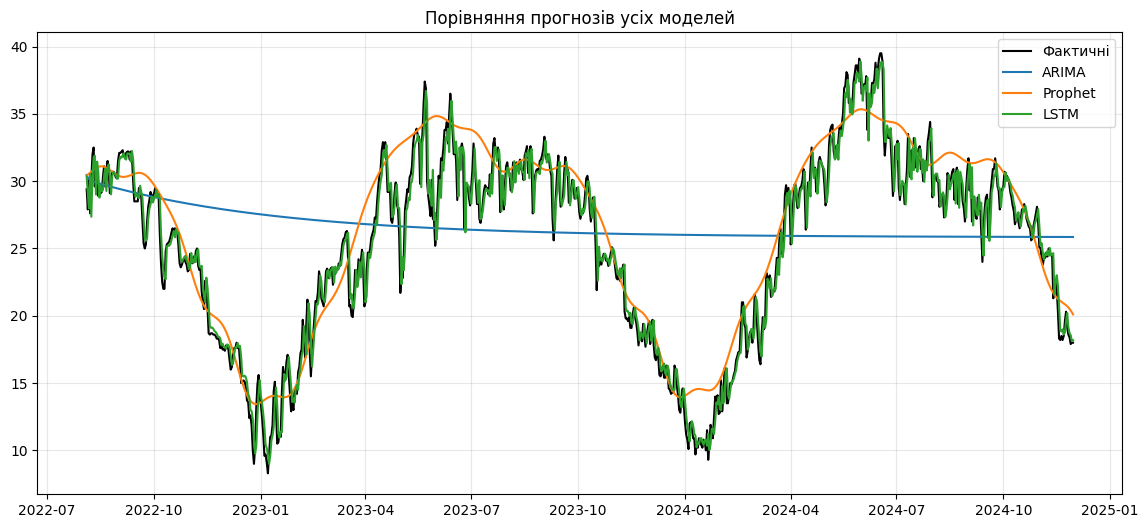

Найкраща модель за RMSE: LSTM


In [ ]:
results_df = pd.DataFrame(results).T.sort_values("RMSE")
display(results_df.round(3))

plt.figure(figsize=(14, 6))
plt.plot(test, label="Фактичні", color="black", linewidth=1.5)
plt.plot(arima_pred, label="ARIMA")
plt.plot(prophet_pred, label="Prophet")
plt.plot(lstm_pred, label="LSTM")
plt.title("Порівняння прогнозів усіх моделей")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best = results_df["RMSE"].idxmin()
print("Найкраща модель за RMSE:", best)

## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


Найкращий результат за точністю (MAE, RMSE, MAPE) демонструє нейронна мережа LSTM, оскільки вона здатна ефективно враховувати складні нелінійні часові залежності між послідовними днями.

Prophet від Meta посідає друге місце та є найбільш зручним інструментом для швидкого розгортання, оскільки автоматично враховує річну сезонність кліматичних даних у Делі.

Класична модель ARIMA виявилася найменш точною на тривалому тестовому проміжку через наявність вираженої річної сезонності, яку простіше моделювати спеціалізованими сезонними архітектурами (SARIMA або Prophet).